# 概要 overview

予測モデルのハイパーパラメータチューニング
Optunaを用いて探索を行う。
交差検証を行い、

作成するモデルは下記
 1. 勾配ブースティング決定木（GBDT）
 2. RandomForest
 3. ニューラルネットワーク（NN）

## ライブラリ読み込み

In [1]:
import torch

# 自作関数 "src"参照
from src.Data_load_And_Preprocess import data_load_and_preprocess
from src.GBDT_param_tuning import Optimize_lightGBM
from src.RndomForest_param_tuning import Optimize_RndomForest
from src.NN_param_tuning import Optimize_NN

## データの読み込み

データの読み込みおよび訓練データ・テストデータの分割
テストデータは最後の精度比較に使用

In [2]:
X_train, X_test, Y_train, Y_test = data_load_and_preprocess()

Number of samples: 1030
Number of features: 8


## GBDTモデルのハイパーパラメータ探索

trainデータに対して交差検証による探索を行う。
探索結果は"./results/GBDT/trials_history.csv"に保存


[I 2026-11-22 15:22:42,483] A new study created in memory with name: subrutin_lgbm_tuning


[I 2026-11-22 15:22:43,016] Trial 0 finished with value: 5.270341149104501 and parameters: {'learning_rate': 0.05, 'num_leaves': 44, 'max_depth': 7, 'min_child_samples': 71, 'subsample': 0.86, 'colsample_bytree': 0.99, 'reg_alpha': 0.1, 'reg_lambda': 0.1}. Best is trial 0 with value: 5.270341149104501.


Trial 1 CV Mean [Avg Best Iter: 378.4] Train RMSE: 3.9267 | Valid RMSE: 5.2703 | 


[I 2026-11-22 15:22:43,398] Trial 1 finished with value: 4.902851224513588 and parameters: {'learning_rate': 0.05, 'num_leaves': 98, 'max_depth': 10, 'min_child_samples': 25, 'subsample': 0.9199999999999999, 'colsample_bytree': 0.64, 'reg_alpha': 1.0, 'reg_lambda': 0.01}. Best is trial 1 with value: 4.902851224513588.


Trial 2 CV Mean [Avg Best Iter: 212.2] Train RMSE: 2.7088 | Valid RMSE: 4.9029 | 


[I 2026-11-22 15:22:43,605] Trial 2 finished with value: 5.145299072352938 and parameters: {'learning_rate': 0.1, 'num_leaves': 87, 'max_depth': 4, 'min_child_samples': 22, 'subsample': 0.62, 'colsample_bytree': 0.84, 'reg_alpha': 1.0, 'reg_lambda': 0.1}. Best is trial 1 with value: 4.902851224513588.


... (2 outputs left out)

Trial 4 CV Mean [Avg Best Iter: 943.8] Train RMSE: 4.7380 | Valid RMSE: 5.7797 | 


[I 2026-11-22 15:22:44,955] Trial 4 finished with value: 5.7326844336326275 and parameters: {'learning_rate': 0.1, 'num_leaves': 49, 'max_depth': 8, 'min_child_samples': 84, 'subsample': 0.8999999999999999, 'colsample_bytree': 0.64, 'reg_alpha': 0.1, 'reg_lambda': 10.0}. Best is trial 1 with value: 4.902851224513588.


Trial 5 CV Mean [Avg Best Iter: 172.0] Train RMSE: 4.6499 | Valid RMSE: 5.7327 | 

ハイパーパラメータチューニング完了！
ベストTrial番号: 1
ベストイテレーション（平均）: 212.2 ラウンド
ベスト検証 RMSE: 4.9029
ベスト訓練 RMSE: 2.7088
ベストパラメータ:
  - learning_rate: 0.05
  - num_leaves: 98
  - max_depth: 10
  - min_child_samples: 25
  - subsample: 0.9199999999999999
  - colsample_bytree: 0.64
  - reg_alpha: 1.0
  - reg_lambda: 0.01


c:\Users\tapap\Desktop\コード置き場\Project01_ConcreteStrength_Regression\src\GBDT_param_tuning.py:147: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  vis_plt.plot_optimization_history(study)


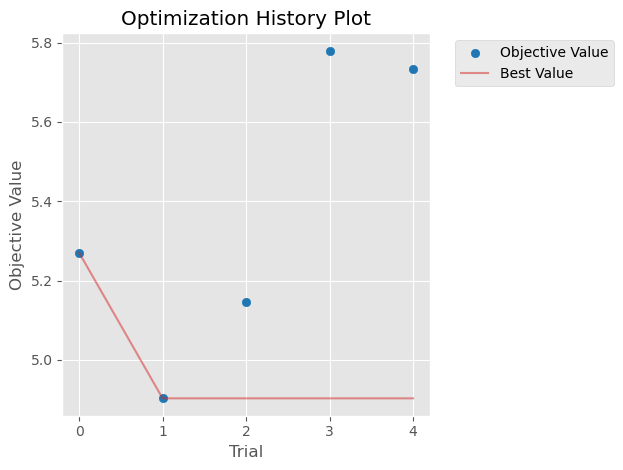

処理時間: 2.89秒


In [5]:
trial_n =5 #Optuna探索試行回数

Optimize_lightGBM(trial_n, X_train, Y_train)

## RndomForestモデルのハイパーパラメータ探索

trainデータに対して交差検証による探索を行う。
探索結果は"./results/RandomForest/trials_history.csv"に保存


[I 2026-11-22 18:08:23,275] A new study created in memory with name: subrutin_lgbm_tuning


[I 2026-11-22 18:08:25,892] Trial 0 finished with value: 9.06804761041419 and parameters: {'max_features': 0.4325775193300805, 'max_depth': 6, 'min_samples_leaf': 17, 'min_samples_split': 20}. Best is trial 0 with value: 9.06804761041419.


Trial 1  Train RMSE: 8.3016 | Valid RMSE: 9.0680 | 


[I 2026-11-22 18:08:29,835] Trial 1 finished with value: 6.941506622725133 and parameters: {'max_features': 0.571793571364571, 'max_depth': 9, 'min_samples_leaf': 4, 'min_samples_split': 9}. Best is trial 1 with value: 6.941506622725133.


Trial 2  Train RMSE: 5.2606 | Valid RMSE: 6.9415 | 


[I 2026-11-22 18:08:33,338] Trial 2 finished with value: 8.29458410424007 and parameters: {'max_features': 0.6611280060903186, 'max_depth': 12, 'min_samples_leaf': 11, 'min_samples_split': 19}. Best is trial 1 with value: 6.941506622725133.


... (2 outputs left out)

Trial 4  Train RMSE: 7.9290 | Valid RMSE: 8.7965 | 


[I 2026-11-22 18:08:39,791] Trial 4 finished with value: 9.316427619222061 and parameters: {'max_features': 0.6207760732489374, 'max_depth': 20, 'min_samples_leaf': 20, 'min_samples_split': 18}. Best is trial 1 with value: 6.941506622725133.


Trial 5  Train RMSE: 8.6130 | Valid RMSE: 9.3164 | 

ハイパーパラメータチューニング完了！
ベストTrial番号: 1
ベスト検証 RMSE: 6.9415
ベスト訓練 RMSE: 5.2606
ベストパラメータ:
  - max_features: 0.571793571364571
  - max_depth: 9
  - min_samples_leaf: 4
  - min_samples_split: 9


c:\Users\tapap\Desktop\コード置き場\Project01_ConcreteStrength_Regression\src\RndomForest_param_tuning.py:141: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  vis_plt.plot_optimization_history(study)


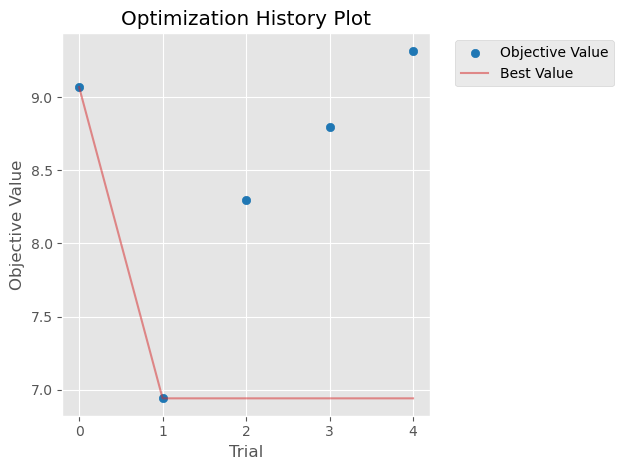

処理時間: 16.94秒


In [3]:
trial_n =5 #Optuna探索試行回数

Optimize_RndomForest(trial_n, X_train, Y_train)

## ニューラルネットワークモデルのハイパーパラメータ探索

trainデータに対して交差検証による探索を行う。
探索結果は"./results/NN/trials_history.csv"に保存

[I 2026-11-23 11:06:28,607] A new study created in memory with name: subrutin_lgbm_tuning


Device: cpu
Epoch [90/300] Train Loss: 0.4449 | Valid Loss: 0.3895 | 
Early Stopping: Epoch 96
Epoch [80/300] Train Loss: 0.4450 | Valid Loss: 0.4426 | 
Early Stopping: Epoch 88
Epoch [100/300] Train Loss: 0.4456 | Valid Loss: 0.4255 | 
Early Stopping: Epoch 107
Epoch [90/300] Train Loss: 0.4458 | Valid Loss: 0.3979 | 
Early Stopping: Epoch 96
Epoch [60/300] Train Loss: 0.4866 | Valid Loss: 0.4016 | 
Early Stopping: Epoch 67


[I 2026-11-23 11:06:58,773] Trial 0 finished with value: 6.867227905387412 and parameters: {'n_layers': 1, 'hidden_dim_0': 32, 'drop_rate': 0.30000000000000004}. Best is trial 0 with value: 6.867227905387412.


Trial 1 CV Mean [Avg Best Iter: 85.8] Train RMSE: 6.4286 | Valid RMSE: 6.8672 | 
Epoch [50/300] Train Loss: 0.4202 | Valid Loss: 0.3852 | 
Early Stopping: Epoch 51
Epoch [30/300] Train Loss: 0.4758 | Valid Loss: 0.4403 | 
Early Stopping: Epoch 39
Epoch [30/300] Train Loss: 0.4598 | Valid Loss: 0.4254 | 
Early Stopping: Epoch 36
Epoch [30/300] Train Loss: 0.4861 | Valid Loss: 0.3881 | 
Early Stopping: Epoch 31
Epoch [40/300] Train Loss: 0.4441 | Valid Loss: 0.3563 | 
Early Stopping: Epoch 48


[I 2026-11-23 11:07:29,888] Trial 1 finished with value: 6.4196858824305725 and parameters: {'n_layers': 3, 'hidden_dim_0': 112, 'hidden_dim_1': 112, 'hidden_dim_2': 80, 'drop_rate': 0.4}. Best is trial 1 with value: 6.4196858824305725.


Trial 2 CV Mean [Avg Best Iter: 36.0] Train RMSE: 5.6478 | Valid RMSE: 6.4197 | 
Epoch [50/300] Train Loss: 0.2596 | Valid Loss: 0.2935 | 
Early Stopping: Epoch 54
Epoch [50/300] Train Loss: 0.2367 | Valid Loss: 0.3608 | 
Early Stopping: Epoch 56
Epoch [40/300] Train Loss: 0.2838 | Valid Loss: 0.3963 | 
Early Stopping: Epoch 45
Epoch [20/300] Train Loss: 0.2965 | Valid Loss: 0.3548 | 
Early Stopping: Epoch 28
Epoch [50/300] Train Loss: 0.2741 | Valid Loss: 0.3274 | 
Early Stopping: Epoch 59


... (3 outputs left out)

Trial 4 CV Mean [Avg Best Iter: 37.4] Train RMSE: 5.9512 | Valid RMSE: 6.6862 | 
Epoch [30/300] Train Loss: 0.4740 | Valid Loss: 0.3734 | 
Early Stopping: Epoch 35
Epoch [60/300] Train Loss: 0.3915 | Valid Loss: 0.4086 | 
Early Stopping: Epoch 61
Epoch [90/300] Train Loss: 0.3689 | Valid Loss: 0.3660 | 
Early Stopping: Epoch 92
Epoch [60/300] Train Loss: 0.4076 | Valid Loss: 0.3552 | 
Early Stopping: Epoch 66
Epoch [60/300] Train Loss: 0.4157 | Valid Loss: 0.3333 | 
Early Stopping: Epoch 66


[I 2026-11-23 11:08:50,677] Trial 4 finished with value: 6.083539865847314 and parameters: {'n_layers': 2, 'hidden_dim_0': 48, 'hidden_dim_1': 32, 'drop_rate': 0.2}. Best is trial 2 with value: 5.566206035958051.


Trial 5 CV Mean [Avg Best Iter: 59.0] Train RMSE: 5.3499 | Valid RMSE: 6.0835 | 

ハイパーパラメータチューニング完了！
ベストTrial番号: 2
ベストイテレーション（平均）: 43.4 ラウンド
ベスト検証 RMSE: 5.5662
ベスト訓練 RMSE: 4.3356
ベストパラメータ:
  - n_layers: 4
  - hidden_dim_0: 64
  - hidden_dim_1: 16
  - hidden_dim_2: 16
  - hidden_dim_3: 16
  - drop_rate: 0.0


c:\Users\tapap\Desktop\コード置き場\Project01_ConcreteStrength_Regression\src\NN_param_tuning.py:180: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  vis_plt.plot_optimization_history(study)


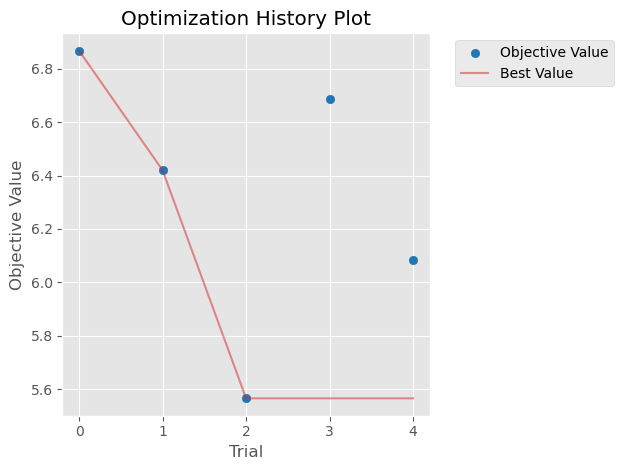

処理時間: 142.86秒


In [3]:
# Device selection
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")

trial_n =5 #Optuna探索試行回数

Optimize_NN(trial_n, X_train, Y_train, device)